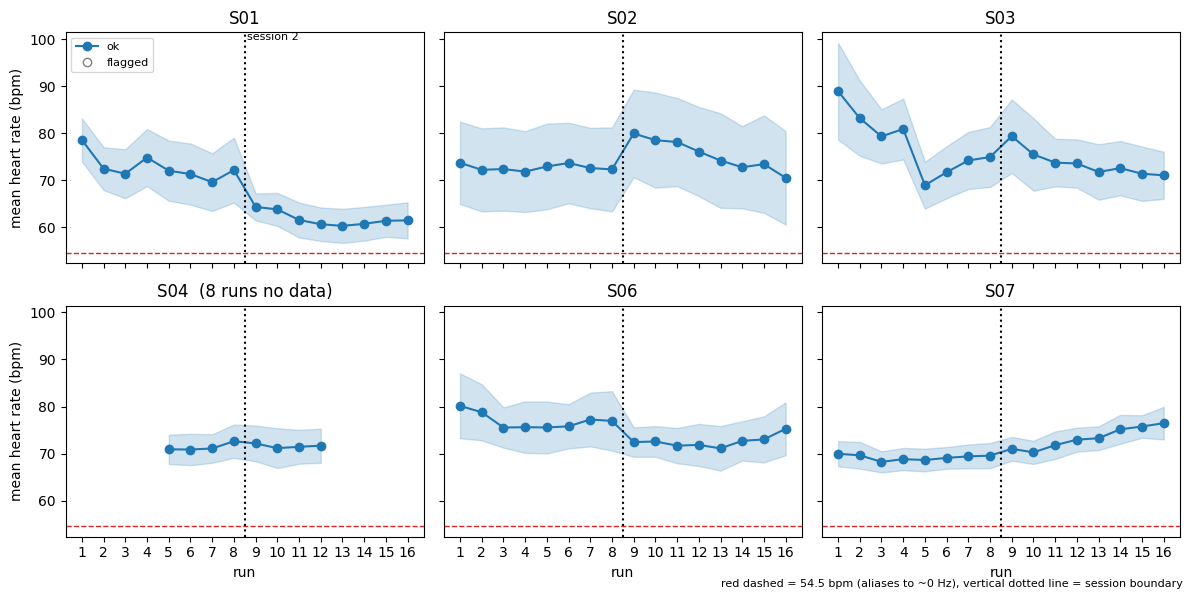

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]    

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, s in zip(axes, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    # line through good runs only; flagged or missing runs leave a gap
    ax.plot(x.run, x.hr_mean.where(good), '-o', color='C0', label='ok')
    ax.fill_between(x.run, (x.hr_mean - x.hr_sd).where(good),
                    (x.hr_mean + x.hr_sd).where(good), color='C0', alpha=0.2)

    # flagged runs (data present but failed QC) as open grey markers
    flagged = ~good & x.hr_mean.notna()
    ax.plot(x.run[flagged], x.hr_mean[flagged], 'o', mfc='none', color='0.5', label='flagged')

    # heart rate whose aliased frequency is ~0 Hz with TR = 1.1 s
    ax.axhline(60 / 1.1, color='C3', ls='--', lw=1)
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2

    n_missing = x.hr_mean.isna().sum()
    ax.set_title(f'{s}' + (f'  ({n_missing} runs no data)' if n_missing else ''))
    ax.set_xticks(range(1, 17))

for ax in axes[n:]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes[::ncol]:
    ax.set_ylabel('mean heart rate (bpm)')

axes[0].legend(fontsize=8, loc='upper left')
fig.text(0.99, 0.01, 'red dashed = 54.5 bpm (aliases to ~0 Hz), vertical dotted line = session boundary', va='bottom',
         ha='right', fontsize=8)

axes[0].text(8.6, axes[0].get_ylim()[1], 'session 2', va='top', fontsize=8)

plt.tight_layout()
plt.show()

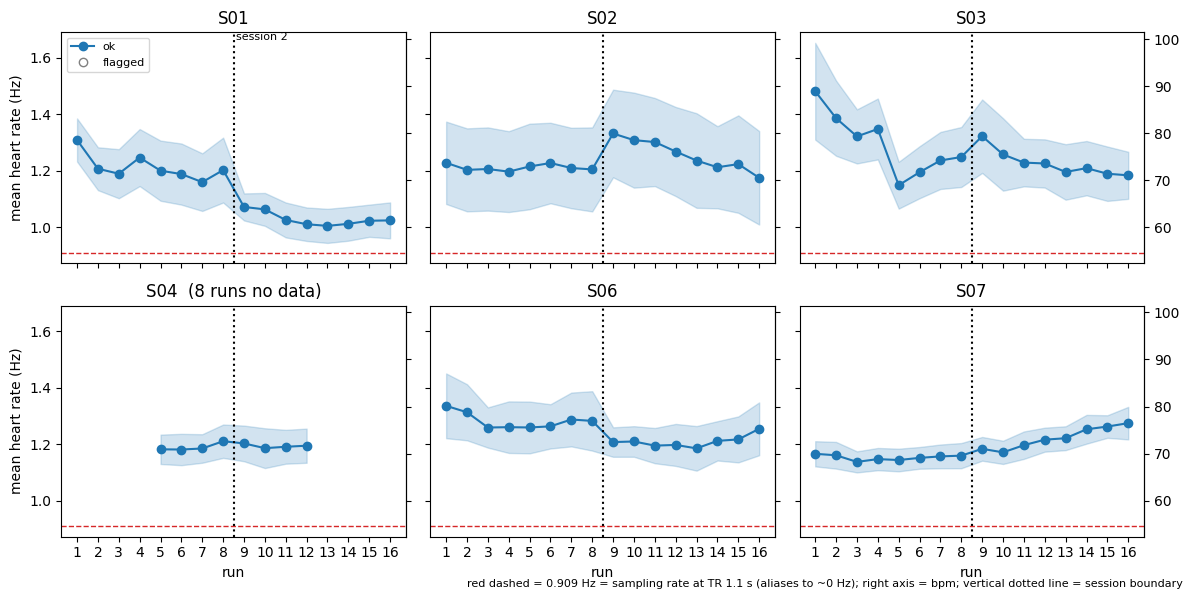

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TR = 1.1
fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]
T['hr_hz'] = T.hr_mean / 60          # mean heart rate in Hz
T['hr_sd_hz'] = T.hr_sd / 60         # its spread within the run, in Hz

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, s in zip(axes, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    # line through good runs only; flagged or missing runs leave a gap
    ax.plot(x.run, x.hr_hz.where(good), '-o', color='C0', label='ok')
    ax.fill_between(x.run, (x.hr_hz - x.hr_sd_hz).where(good),
                    (x.hr_hz + x.hr_sd_hz).where(good), color='C0', alpha=0.2)

    # flagged runs (data present but failed QC) as open grey markers
    flagged = ~good & x.hr_hz.notna()
    ax.plot(x.run[flagged], x.hr_hz[flagged], 'o', mfc='none', color='0.5', label='flagged')

    # heart rate whose aliased frequency is ~0 Hz: the sampling rate 1/TR
    ax.axhline(1 / TR, color='C3', ls='--', lw=1)
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2

    # bpm on the right-hand axis, for reference
    sec = ax.secondary_yaxis('right', functions=(lambda hz: hz * 60, lambda bpm: bpm / 60))
    if ax not in axes[ncol - 1::ncol] and ax is not axes[n - 1]:
        sec.set_yticklabels([])

    n_missing = x.hr_hz.isna().sum()
    ax.set_title(f'{s}' + (f'  ({n_missing} runs no data)' if n_missing else ''))
    ax.set_xticks(range(1, 17))

for ax in axes[n:]:
    ax.set_visible(False)
for ax in axes[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes[::ncol]:
    ax.set_ylabel('mean heart rate (Hz)')

axes[0].legend(fontsize=8, loc='upper left')
fig.text(0.99, 0.01, f'red dashed = {1/TR:.3f} Hz = sampling rate at TR {TR} s (aliases to ~0 Hz); '
         'right axis = bpm; vertical dotted line = session boundary',
         va='bottom', ha='right', fontsize=8)

axes[0].text(8.6, axes[0].get_ylim()[1], 'session 2', va='top', fontsize=8)

plt.tight_layout()
plt.show()

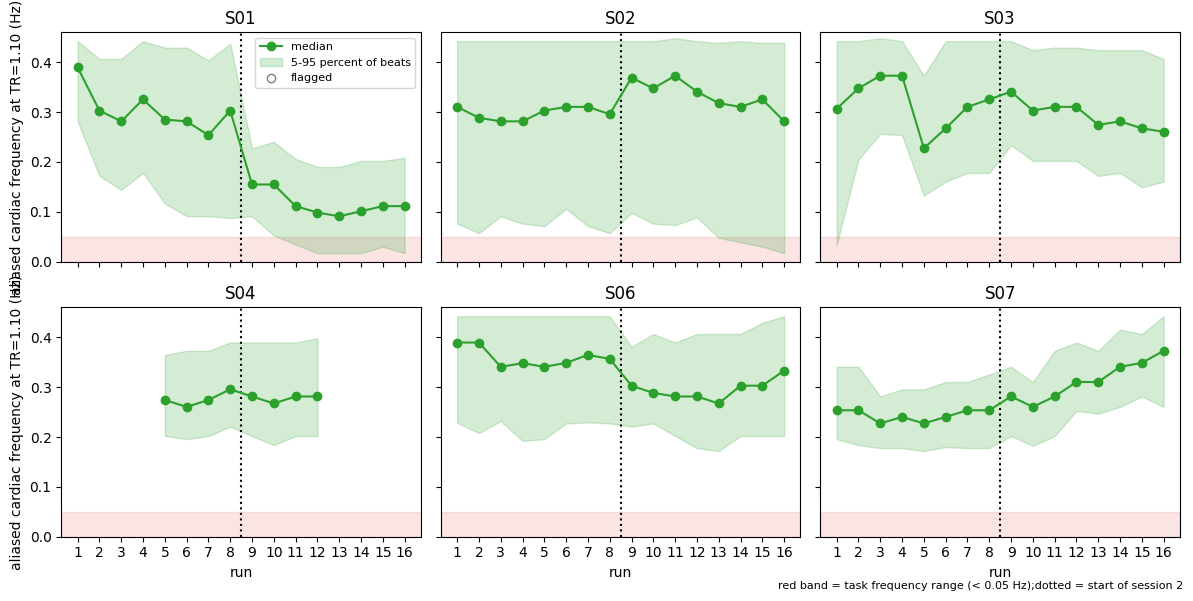

In [18]:

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_1_10.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]    

fig2, axes2 = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes2 = np.atleast_1d(axes2).ravel()

for ax, s in zip(axes2, subjects):
    x = T[T.subj == s].sort_values('run')
    good = x.status == 'ok'

    ax.axvline(8.5, color='k', ls=':', lw=1.5)                 # start of session 2
    ax.axhspan(0, 0.05, color='C3', alpha=0.12, zorder=0)      # task frequency range

    ax.plot(x.run, x.alias_med.where(good), '-o', color='C2', label='median')
    ax.fill_between(x.run, x.alias_p05.where(good), x.alias_p95.where(good),
                    color='C2', alpha=0.2, label='5-95 percent of beats')

    flagged = ~good & x.alias_med.notna()
    ax.plot(x.run[flagged], x.alias_med[flagged], 'o', mfc='none', color='0.5', label='flagged')

    ax.set_title(s)
    ax.set_xticks(range(1, 17))
    ax.set_ylim(0, 0.46)

for ax in axes2[n:]:
    ax.set_visible(False)
for ax in axes2[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes2[::ncol]:
    ax.set_ylabel('aliased cardiac frequency at TR=1.10 (Hz)')

axes2[0].legend(fontsize=8, loc='upper right')
fig2.text(0.99, 0.01, 'red band = task frequency range (< 0.05 Hz);'
          'dotted = start of session 2', ha='right', fontsize=8)
plt.tight_layout()
plt.show()

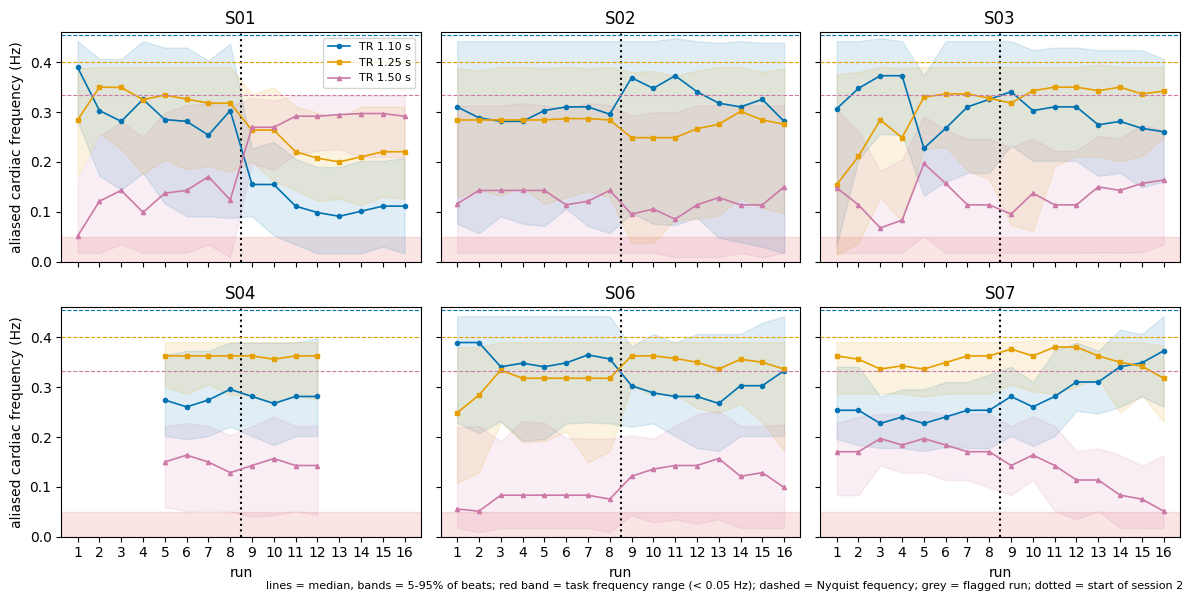

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/hr_alias_by_run_TR_{}.tsv'
trs = {'1_10': (1.10, '#0072B2', 'o'),          # file tag: (TR in s, colour)
       '1_25': (1.25, '#E69F00', 's'),
       '1_50': (1.50, '#CC79A7', '^')}

# ---- load all three tables ----
tabs = {}
for tag, (tr, col, mk) in trs.items():
    T = pd.read_csv(base.format(tag), sep='\t')
    tabs[tag] = T[~T.subj.isin(['S05', 'S09'])]

subjects = tabs['1_10'].subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

fig2, axes2 = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=True)
axes2 = np.atleast_1d(axes2).ravel()

for ax, s in zip(axes2, subjects):
    ax.axvline(8.5, color='k', ls=':', lw=1.5)                 # start of session 2
    ax.axhspan(0, 0.05, color='C3', alpha=0.12, zorder=0)      # task frequency range

    # flagged runs (same for every TR): grey background
    x0 = tabs['1_10'][tabs['1_10'].subj == s]
    for r in x0.run[(x0.status != 'ok') & x0.alias_med.notna()]:
        ax.axvspan(r - 0.5, r + 0.5, color='0.85', zorder=0)

    for tag, (tr, col, mk) in trs.items():
        x = tabs[tag][tabs[tag].subj == s].sort_values('run')
        good = x.status == 'ok'
        ax.plot(x.run, x.alias_med.where(good), marker=mk, color=col, ms=3, lw=1.2,
                label=f'TR {tr:.2f} s')
        ax.fill_between(x.run, x.alias_p05.where(good), x.alias_p95.where(good),
                        color=col, alpha=0.12)
        ax.axhline(1 / (2 * tr), color=col, ls='--', lw=0.8)   # Nyquist: highest possible alias

    ax.set_title(s)
    ax.set_xticks(range(1, 17))
    ax.set_ylim(0, 0.46)

for ax in axes2[n:]:
    ax.set_visible(False)
for ax in axes2[(nrow - 1) * ncol:]:
    ax.set_xlabel('run')
for ax in axes2[::ncol]:
    ax.set_ylabel('aliased cardiac frequency (Hz)')

axes2[0].legend(fontsize=8, loc='upper right')
fig2.text(0.99, 0.01, 'lines = median, bands = 5-95% of beats; red band = task frequency range (< 0.05 Hz); '
          'dashed = Nyquist fequency; grey = flagged run; dotted = start of session 2',
          ha='right', fontsize=8)
plt.tight_layout()
plt.show()

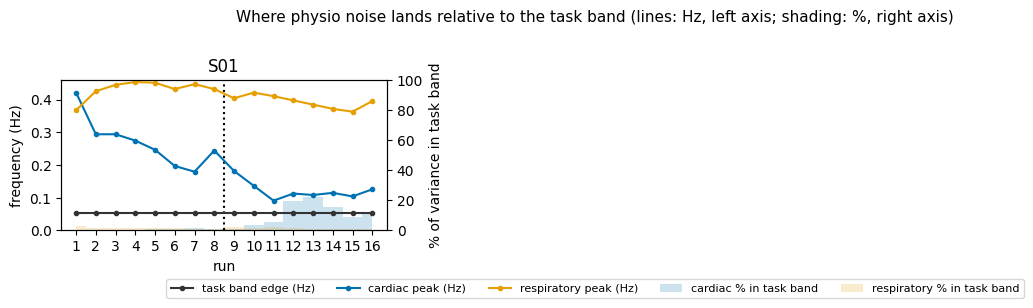

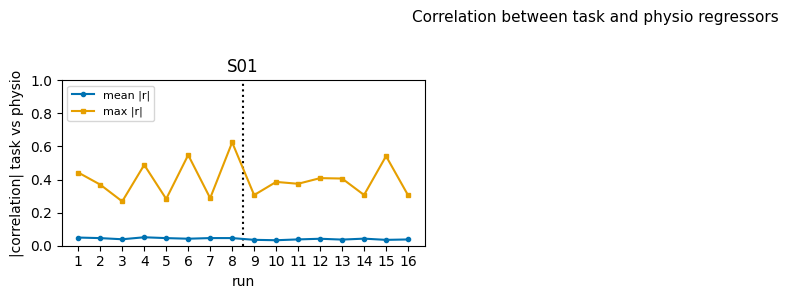

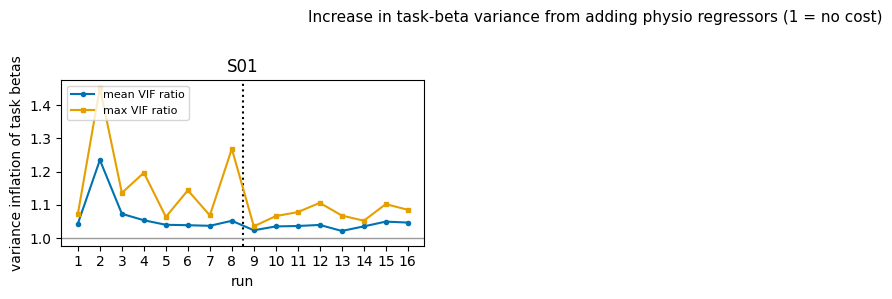

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/physio_design_check.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

blue, orange, grey = '#0072B2', '#E69F00', '0.2'      # cardiac, respiratory, task


def subject_grid(sharey=True):
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=sharey)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    for ax in axes[(nrow - 1) * ncol:]:
        ax.set_xlabel('run')
    return fig, axes


def run_axis(ax, s):
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2
    ax.set_xticks(range(1, 17))
    ax.set_title(s)


# ---------------- figure 1: frequencies (left) and % in task band (right) ----------------
fig1, axes1 = subject_grid()
for i, (ax, s) in enumerate(zip(axes1, subjects)):
    x = T[T.subj == s].sort_values('run')
    run_axis(ax, s)
    h1 = ax.plot(x.run, x.task_cut_hz, '-o', color=grey, ms=3, label='task band edge (Hz)')
    h2 = ax.plot(x.run, x.card_peak_hz, '-o', color=blue, ms=3, label='cardiac peak (Hz)')
    h3 = ax.plot(x.run, x.resp_peak_hz, '-o', color=orange, ms=3, label='respiratory peak (Hz)')
    ax.set_ylim(0, 0.46)

    ax2 = ax.twinx()                                    # right axis: percentages, shaded
    h4 = ax2.fill_between(x.run, 0, x.card_pct_in_taskband, step='mid',
                          color=blue, alpha=0.2, lw=0, label='cardiac % in task band')
    h5 = ax2.fill_between(x.run, 0, x.resp_pct_in_taskband, step='mid',
                          color=orange, alpha=0.2, lw=0, label='respiratory % in task band')
    ax2.set_ylim(0, 100)
    if i % ncol == ncol - 1 or i == n - 1:
        ax2.set_ylabel('% of variance in task band')
    else:
        ax2.set_yticklabels([])

    # draw the frequency lines (left axis) on top of the shading
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

   
    if i == 0:
        handles = h1 + h2 + h3 + [h4,h5]
for ax in axes1[::ncol]:
    ax.set_ylabel('frequency (Hz)')
fig1.legend(handles, [h.get_label() for h in handles], loc='lower center', ncol=5, fontsize=8,
            bbox_to_anchor=(0.5, 0.0))
fig1.suptitle('Where physio noise lands relative to the task band (lines: Hz, left axis; shading: %, right axis)',
              fontsize=11)
fig1.tight_layout(rect=(0, 0.05, 1, 0.97))

# ---------------- figure 2: correlations ----------------
fig2, axes2 = subject_grid()
for ax, s in zip(axes2, subjects):
    x = T[T.subj == s].sort_values('run')
    run_axis(ax, s)
    ax.plot(x.run, x.mean_abs_r, '-o', color=blue, ms=3, label='mean |r|')
    ax.plot(x.run, x.max_abs_r, '-s', color=orange, ms=3, label='max |r|')
    ax.set_ylim(0, 1)
for ax in axes2[::ncol]:
    ax.set_ylabel('|correlation| task vs physio')
axes2[0].legend(fontsize=8, loc='upper left')
fig2.suptitle('Correlation between task and physio regressors', fontsize=11)
fig2.tight_layout(rect=(0, 0, 1, 0.97))

# ---------------- figure 3: variance inflation ----------------
fig3, axes3 = subject_grid()
for ax, s in zip(axes3, subjects):
    x = T[T.subj == s].sort_values('run')
    run_axis(ax, s)
    ax.axhline(1, color='0.6', lw=1)                    # 1 = no cost
    ax.plot(x.run, x.vif_mean, '-o', color=blue, ms=3, label='mean VIF ratio')
    ax.plot(x.run, x.vif_max, '-s', color=orange, ms=3, label='max VIF ratio')
for ax in axes3[::ncol]:
    ax.set_ylabel('variance inflation of task betas')
axes3[0].legend(fontsize=8, loc='upper left')
fig3.suptitle('Increase in task-beta variance from adding physio regressors (1 = no cost)', fontsize=11)
fig3.tight_layout(rect=(0, 0, 1, 0.97))

plt.show()

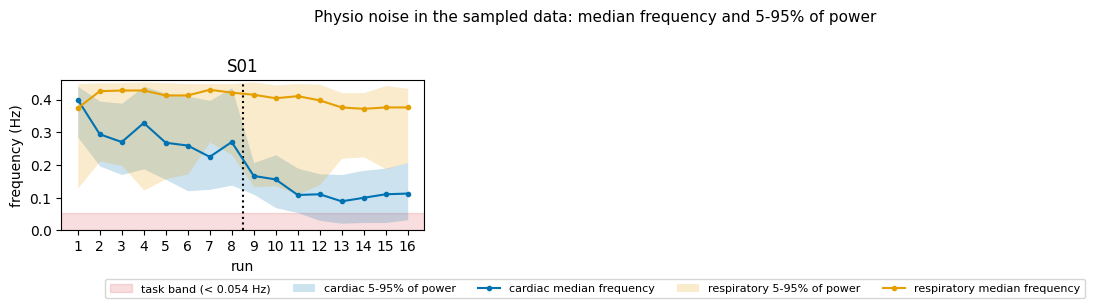

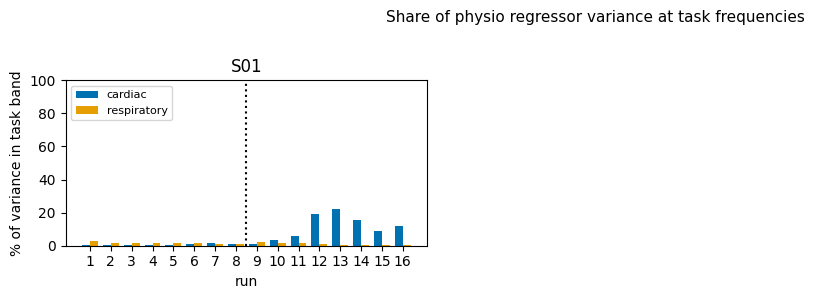

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/physio_design_check_percentiles.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]

subjects = T.subj.unique()
n = len(subjects)
ncol = 3
nrow = int(np.ceil(n / ncol))

blue, orange, grey = '#0072B2', '#E69F00', '0.2'      # cardiac, respiratory, task


def subject_grid(sharey=True):
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow), sharex=True, sharey=sharey)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.set_visible(False)
    for ax in axes[(nrow - 1) * ncol:]:
        ax.set_xlabel('run')
    return fig, axes


def run_axis(ax, s):
    ax.axvline(8.5, color='k', ls=':', lw=1.5)          # boundary between session 1 and 2
    ax.set_xticks(range(1, 17))
    ax.set_title(s)


# ---------------- figure 1: where the physio noise sits in frequency ----------------
fig1, axes1 = subject_grid()
for ax, s in zip(axes1, subjects):
    x = T[T.subj == s].sort_values('run')
    run_axis(ax, s)
    ax.axhspan(0, x.task_cut_hz.median(), color='C3', alpha=0.15, zorder=0,
               label=f'task band (< {x.task_cut_hz.median():.3f} Hz)')
    ax.fill_between(x.run, x.card_f05, x.card_f95, color=blue, alpha=0.2, lw=0,
                    label='cardiac 5-95% of power')
    ax.plot(x.run, x.card_f50, '-o', color=blue, ms=3, label='cardiac median frequency')

    ax.fill_between(x.run, x.resp_f05, x.resp_f95, color=orange, alpha=0.2, lw=0,
                    label='respiratory 5-95% of power')
    ax.plot(x.run, x.resp_f50, '-o', color=orange, ms=3, label='respiratory median frequency')

    ax.set_ylim(0, 0.46)
for ax in axes1[::ncol]:
    ax.set_ylabel('frequency (Hz)')
h, l = axes1[0].get_legend_handles_labels()
fig1.legend(h, l, loc='lower center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, 0.0))
fig1.suptitle('Physio noise in the sampled data: median frequency and 5-95% of power', fontsize=11)
fig1.tight_layout(rect=(0, 0.05, 1, 0.97))

# ---------------- figure 2: % of physio variance inside the task band ----------------
fig2, axes2 = subject_grid()
w = 0.38
for ax, s in zip(axes2, subjects):
    x = T[T.subj == s].sort_values('run')
    run_axis(ax, s)
    ax.bar(x.run - w / 2, x.card_pct_in_taskband, width=w, color=blue, label='cardiac')
    ax.bar(x.run + w / 2, x.resp_pct_in_taskband, width=w, color=orange, label='respiratory')
    ax.set_ylim(0, 100)
for ax in axes2[::ncol]:
    ax.set_ylabel('% of variance in task band')
axes2[0].legend(fontsize=8, loc='upper left')
fig2.suptitle('Share of physio regressor variance at task frequencies', fontsize=11)
fig2.tight_layout(rect=(0, 0, 1, 0.97))

plt.show()

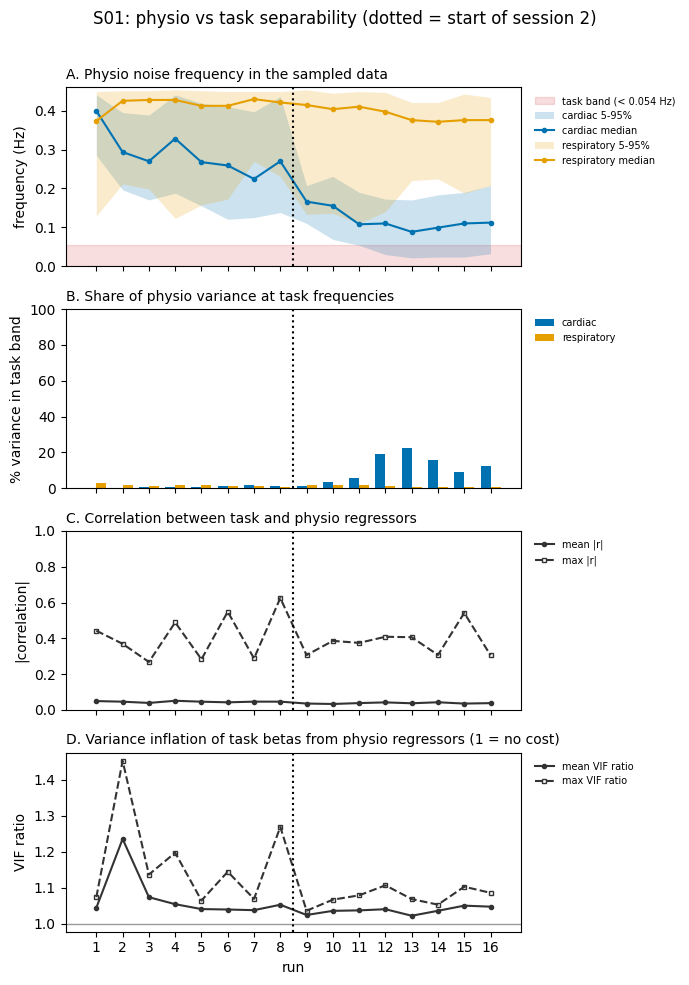

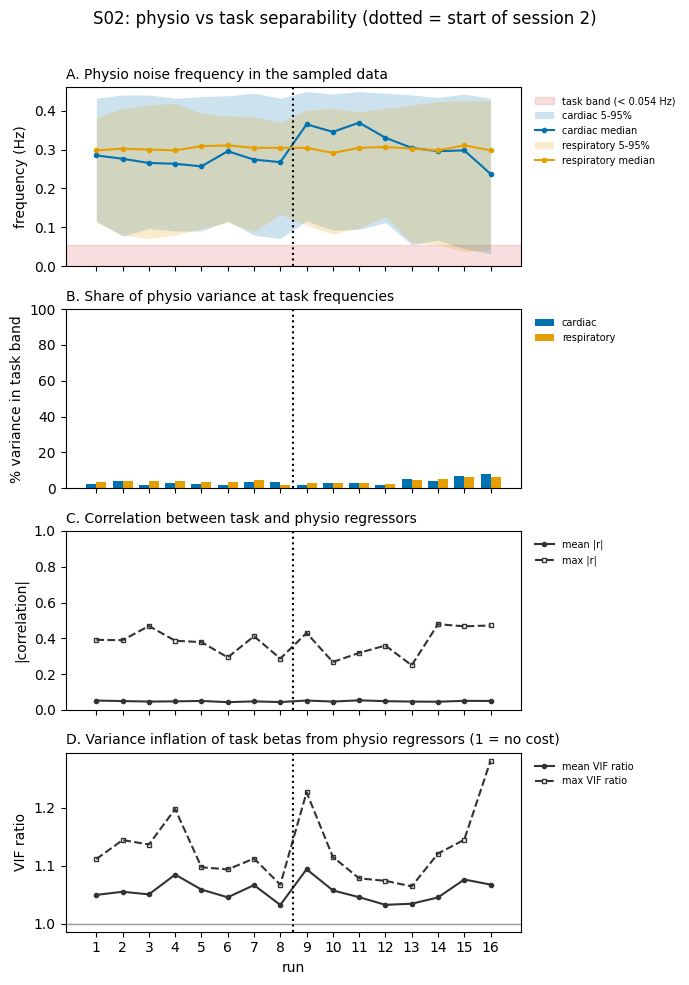

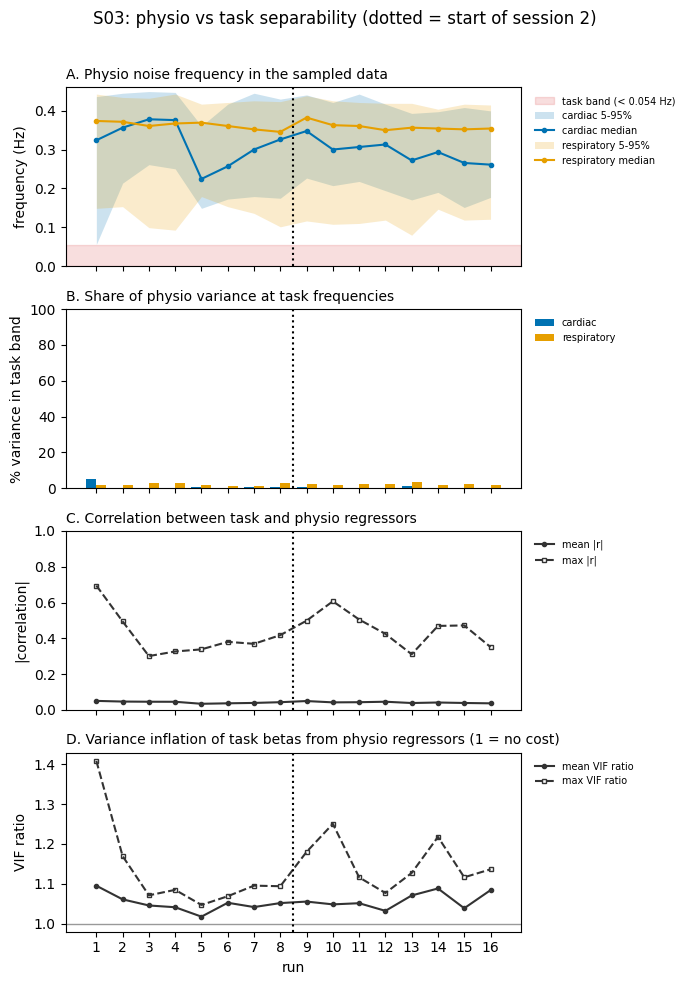

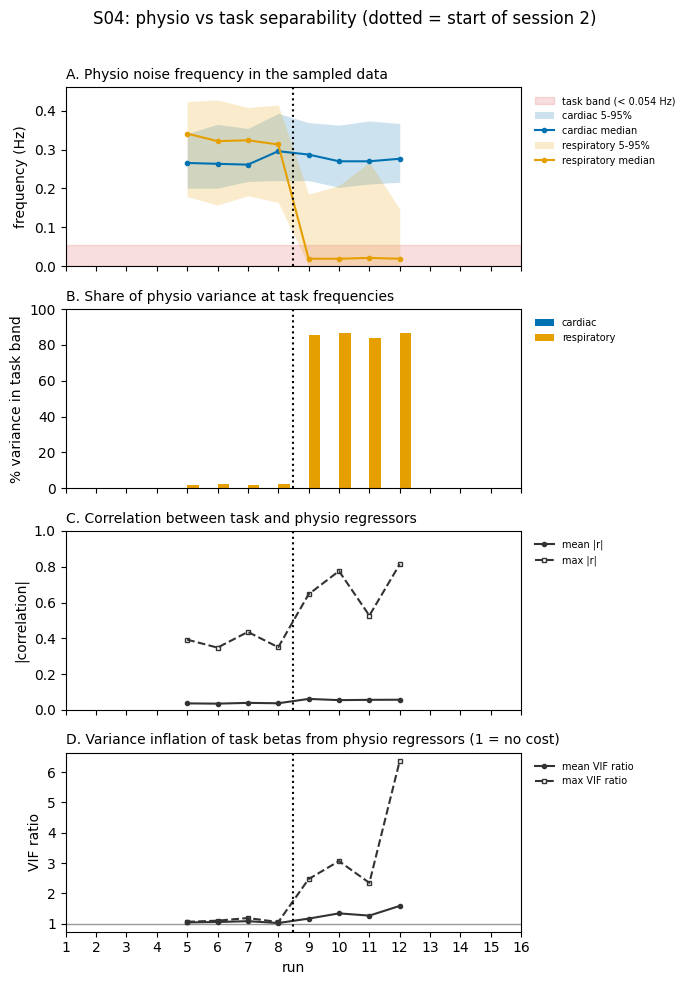

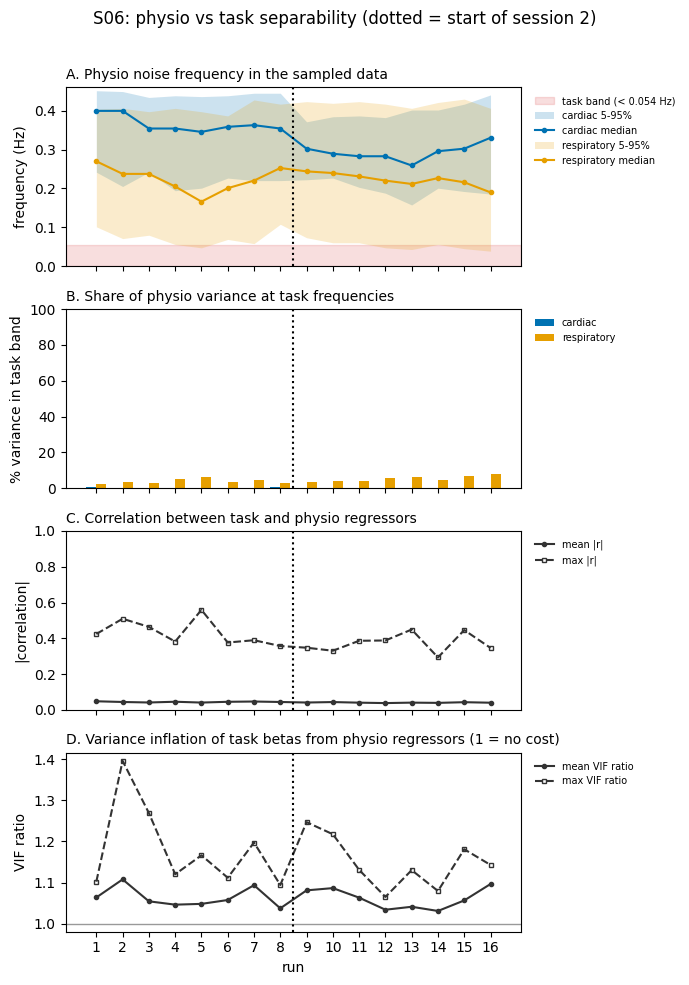

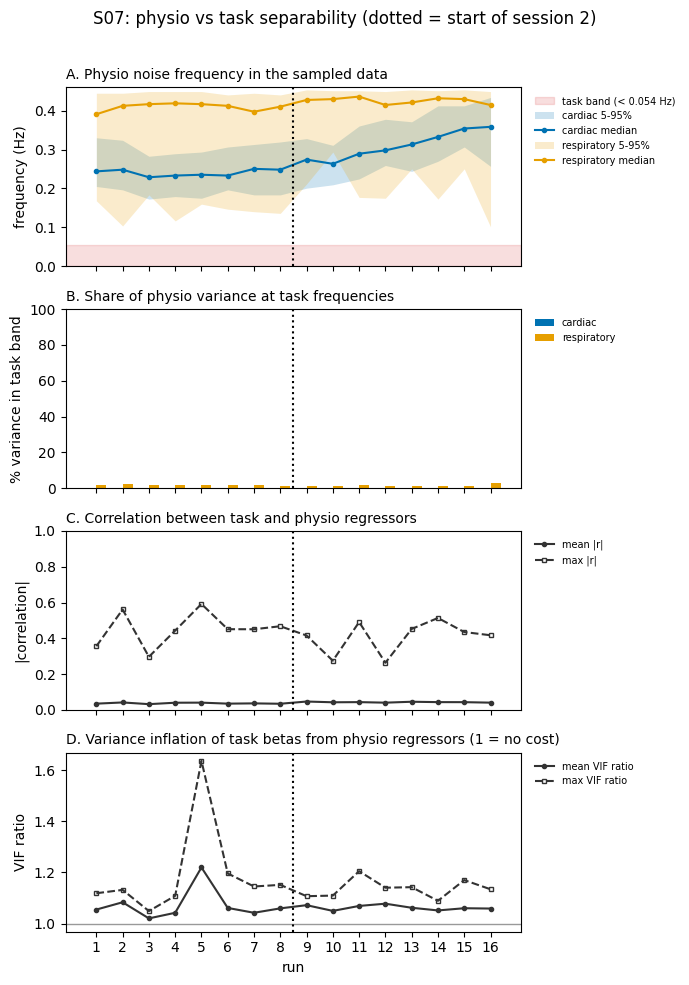

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

fname = '/Volumes/diedrichsen_data$/data/Cerebellum/Olive7T/physio/physio_design_check_all.tsv'
T = pd.read_csv(fname, sep='\t')
T = T[~T.subj.isin(['S05', 'S09'])]
blue, orange = '#0072B2', '#E69F00'


for s in T.subj.unique():
    x = T[T.subj == s].sort_values('run')
    fig, ax = plt.subplots(4, 1, figsize=(7, 10), sharex=True)

    # 1. frequency: median and 5-95% of power, task band shaded
    cut = x.task_cut_hz.median()
    ax[0].axhspan(0, cut, color='C3', alpha=0.15, label=f'task band (< {cut:.3f} Hz)')
    ax[0].fill_between(x.run, x.card_f05, x.card_f95, color=blue, alpha=0.2, lw=0, label='cardiac 5-95%')
    ax[0].plot(x.run, x.card_f50, '-o', color=blue, ms=3, label='cardiac median')
    ax[0].fill_between(x.run, x.resp_f05, x.resp_f95, color=orange, alpha=0.2, lw=0, label='respiratory 5-95%')
    ax[0].plot(x.run, x.resp_f50, '-o', color=orange, ms=3, label='respiratory median')
    ax[0].set_ylim(0, 0.46)
    ax[0].set_ylabel('frequency (Hz)')
    ax[0].set_title('A. Physio noise frequency in the sampled data', loc='left', fontsize=10)

    # 2. share of physio variance at task frequencies
    w = 0.38
    ax[1].bar(x.run - w / 2, x.card_pct_in_taskband, width=w, color=blue, label='cardiac')
    ax[1].bar(x.run + w / 2, x.resp_pct_in_taskband, width=w, color=orange, label='respiratory')
    ax[1].set_ylim(0, 100)
    ax[1].set_ylabel('% variance in task band')
    ax[1].set_title('B. Share of physio variance at task frequencies', loc='left', fontsize=10)

    # 3. correlations between task and physio regressors
    ax[2].plot(x.run, x.mean_abs_r, '-o', color='0.2', ms=3, label='mean |r|')
    ax[2].plot(x.run, x.max_abs_r, '--s', color='0.2', ms=3, mfc='none', label='max |r|')
    ax[2].set_ylim(0, 1)
    ax[2].set_ylabel('|correlation|')
    ax[2].set_title('C. Correlation between task and physio regressors', loc='left', fontsize=10)

    # 4. variance inflation of task betas
    ax[3].axhline(1, color='0.6', lw=1)
    ax[3].plot(x.run, x.vif_mean, '-o', color='0.2', ms=3, label='mean VIF ratio')
    ax[3].plot(x.run, x.vif_max, '--s', color='0.2', ms=3, mfc='none', label='max VIF ratio')
    ax[3].set_ylabel('VIF ratio')
    ax[3].set_title('D. Variance inflation of task betas from physio regressors (1 = no cost)',
                    loc='left', fontsize=10)

    for a in ax:
        a.axvline(8.5, color='k', ls=':', lw=1.5)               # session boundary
        a.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)
    ax[3].set_xlabel('run')
    ax[3].set_xticks(range(1, 17))
    fig.suptitle(f'{s}: physio vs task separability (dotted = start of session 2)', fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()